# PS 2 — Tablice podstawowych rozkładów i Python

**Statystyka Matematyczna — Data Science**

**Wersja dla grupy PS 2**

**Imię i nazwisko:** Marcin Zubowski  
**Data:** 12.10.2026

## Cel zajęć

Na wykładzie przypomnieliśmy cztery rozkłady, które będą wracały w statystyce matematycznej: $N$, $t$, $\chi^2$ i $F$.

Na PS będziemy:
- odczytywać kwantyle i prawdopodobieństwa z tablic,
- sprawdzać je w Pythonie (`scipy.stats`),
- rozróżniać `cdf`, `sf` i `ppf`,
- interpretować liczbę stopni swobody,
- porównywać kształty rozkładów.

**Ważne:** najpierw wykonaj rachunek lub odczyt z tablic, a dopiero potem sprawdź wynik w Pythonie.

W miejscach **Najpierw pomyśl** wpisz odpowiedź przed uruchomieniem kodu.  
W miejscach **Wniosek** podaj krótką interpretację, a nie tylko liczbę.


## 0. Przygotowanie

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t, chi2, f

## 1. Trzy funkcje, które będą nam potrzebne

W `scipy.stats`:

- `cdf(x)` oblicza $P(X\le x)$,
- `sf(x)` oblicza $P(X>x)$,
- `ppf(p)` zwraca kwantyl $x_p$, dla którego $P(X\le x_p)=p$.

### Najpierw pomyśl

Jeżeli tablica podaje wartość krytyczną z **prawego ogona** na poziomie $\alpha=0.05$, to jakiego argumentu użyjesz w `ppf`?

**Odpowiedź:** 1 - 0,05 = 0,95


In [23]:
# Uzupełnij:
alpha = 0.05
p_do_ppf = 1 - alpha   # UZUPEŁNIJ
print(p_do_ppf)

0.95


# 2. Rozkład normalny $N(0,1)$

Dla $Z\sim N(0,1)$ wyznacz z tablic lub znanych wartości kwantyl $z_p$ dla

$p=0.95$.

**Wynik z tablic:** $z_p\approx$ 1,65

Teraz sprawdź wynik w Pythonie.


In [24]:
p = 0.95
z = norm.ppf(p)   # UZUPEŁNIJ: użyj norm.ppf(...)
print("kwantyl =", z)

kwantyl = 1.6448536269514722


### Prawdopodobieństwo

Oblicz najpierw bez Pythona, korzystając z tablic:

$P(Z\le 1.645)$.

**Wynik z tablic:** 0,9505

Następnie sprawdź:


In [25]:
x = 1.645
p = norm.cdf(x)   # UZUPEŁNIJ: norm.cdf(...)
print(p)

0.9500150944608786


### Wniosek

Czy wynik z Pythona zgadza się z tablicą? Jaką różnicę zauważasz w dokładności?

Tak, wyniki zgadzają się z tablicami. Różnice w dokładności widać przez wartości tablic (Mamy wartości dla 1,64 i 1,65 ale nie mamy wartości dla 1,645 przez co wynik odczytany z tablic nie będzie w 100% dokładny).


# 3. Rozkład $t$-Studenta

Niech $T\sim t(\nu)$, gdzie $\nu=12$.

Wyznacz kwantyl $t_p$ dla $p=0.995$.

**Najpierw tablica:** $t_p\approx$ 3,055

**Potem Python:**


In [26]:
nu = 12
p = 0.995
t_kw = t.ppf(p, nu)   # UZUPEŁNIJ: t.ppf(...)
print(t_kw)

3.0545395893929013


Teraz oblicz $P(T>2.179)$ dla $\nu=12$.

**Najpierw pomyśl:** czy użyjesz `cdf` czy `sf`?

sf()


In [27]:
nu = 12
x = 2.179
p_prawy_ogon = t.sf(x, nu)   # UZUPEŁNIJ
print(p_prawy_ogon)

0.024991622963529296


## 4. Jak stopnie swobody zmieniają rozkład $t$?

Porównaj $t(3)$, $t(10)$, $t(30)$ i $N(0,1)$.


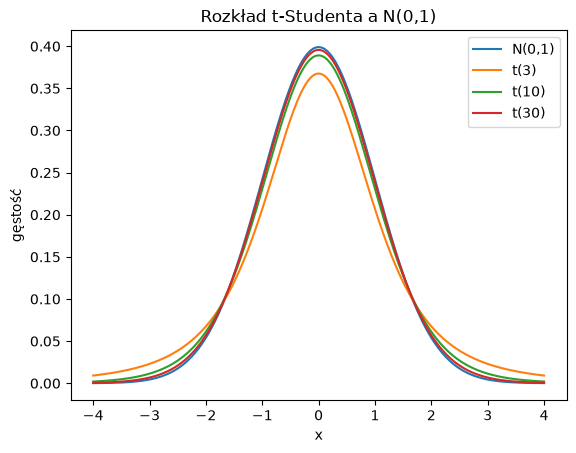

In [28]:
x = np.linspace(-4, 4, 400)

plt.plot(x, norm.pdf(x), label="N(0,1)")
for nu in [3, 10, 30]:
    plt.plot(x, t.pdf(x, df=nu), label=f"t({nu})")

plt.legend()
plt.title("Rozkład t-Studenta a N(0,1)")
plt.xlabel("x")
plt.ylabel("gęstość")
plt.show()

### Wniosek

1. Który rozkład ma grubsze ogony?  
2. Co dzieje się z rozkładem $t$, gdy rośnie $\nu$?

Odpowiedzi:
1. Najgrubsze ogony ma rozkład t-studenta z parametrewm 3
2. Gdy rośnie wartość n, to rozkład t-studenta bardziej przypomina rozkład normalny


# 5. Rozkład $\chi^2$

Niech $X\sim\chi^2(\nu)$, gdzie $\nu=6$.

W tablicach często podaje się $\chi^2_{\alpha,\nu}$ tak, że

$P(X>\chi^2_{\alpha,\nu})=\alpha$.

Wyznacz kwantyl dla $p=0.975$.

**Wynik z tablic:** 14,449


In [29]:
nu = 6
p = 0.975
chi_kw = chi2.ppf(p, nu)   # UZUPEŁNIJ: chi2.ppf(...)
print(chi_kw)

14.44937533544792


Sprawdź teraz prawdopodobieństwo prawego ogona:

$P(X>12.59)$.

**Przewidywanie na podstawie tablic:** 0,05


In [30]:
nu = 6
x = 12.59
p = chi2.sf(x, nu)   # UZUPEŁNIJ: chi2.sf(...)
print(p)

0.05002901173891519


## 6. Kształt rozkładu $\chi^2$

Narysuj gęstości dla $\nu=2,5,10,30$.


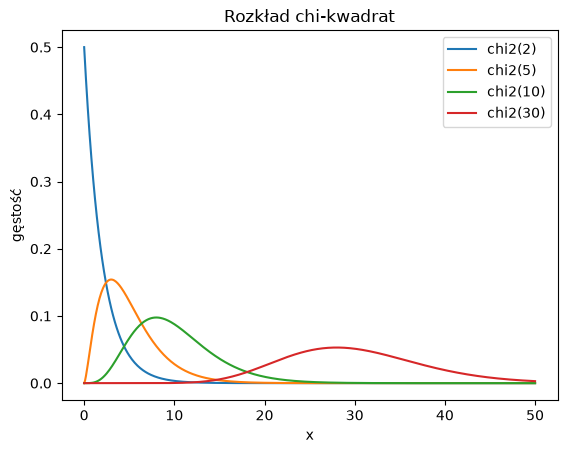

In [31]:
x = np.linspace(0, 50, 500)

for nu in [2, 5, 10, 30]:
    plt.plot(x, chi2.pdf(x, df=nu), label=f"chi2({nu})")

plt.legend()
plt.title("Rozkład chi-kwadrat")
plt.xlabel("x")
plt.ylabel("gęstość")
plt.show()

### Wniosek

Jak zmienia się asymetria rozkładu, gdy rośnie liczba stopni swobody?

Razem z rosnącą wartością stopni swobody, rozkład robi się coraz bardziej symetryczny.


# 7. Rozkład $F$-Snedecora

Niech $Y\sim F(m,n)$, gdzie $m=4$ i $n=12$.

Wyznacz kwantyl dla $p=0.975$.

**Wynik z tablic:** 4,12


In [32]:
m = 4
n = 12
p = 0.975
f_kw = f.ppf(p, m, n)   # UZUPEŁNIJ: f.ppf(...)
print(f_kw)

4.121208618523441


Oblicz $P(Y>4.12)$.

**Najpierw oszacuj/odczytaj z tablic:** 0,025


In [33]:
m = 4
n = 12
x = 4.12
p = f.sf(x, m, n)   # UZUPEŁNIJ
print(p)

0.02502307236842735


# 8. Własność rozkładu $F$

Jeżeli $Y\sim F(m,n)$, to

$1/Y\sim F(n,m)$.

Sprawdzimy tę własność numerycznie dla kwantyli. Uzupełnij kod.


In [34]:
m = 4
n = 12
alpha = 0.05

prawy = f.ppf(1-alpha, dfn=m, dfd=n)
lewy_po_odwroceniu = 1/f.ppf(alpha, dfn=n, dfd=m)   # UZUPEŁNIJ odpowiednim kwantylem F(n,m)

print("kwantyl prawostronny =", prawy)
print("wartość z własności 1/F =", lewy_po_odwroceniu)

kwantyl prawostronny = 3.2591667269012494
wartość z własności 1/F = 3.2591667269012494


### Wniosek

Czy wartości są zgodne? Dlaczego w rozkładzie $F$ trzeba uważać na kolejność stopni swobody?

Tak, wartości są zgodne. W rozkładzie F należy uważać na kolejność stopni swobody, ponieważ tablice nie są symetryczne.


# 9. Jedno zadanie — cztery narzędzia

Dla wybranego kwantyla z dzisiejszych zajęć porównaj:

1. wynik z tablic,
2. wynik z Pythona,
3. jeśli masz dostęp — wynik z Excela,
4. jeśli znasz R — wynik z odpowiedniej funkcji `q...`.

Uzupełnij tabelę:

$T\sim t(\nu)$, gdzie $\nu=12$.

Wyznaczam kwantyl $t_p$ dla $p=0.995$.

| Narzędzie | Wynik |
|---|---:|
| Tablice | 3.05454 |
| Python | 3.0545395893929013 |
| Excel | - |
| R | - |

**Czy wszystkie narzędzia odpowiadają na to samo pytanie statystyczne?**  
Tak, wszystkie narzędzia odpowiadjaą na to samo pytanie statystyczne oraz podają przybliżone do siebie wyniki


# 10. Zadanie samodzielne — grupa PS 2

Dla $X\sim \chi^2(8)$ znajdź $a$, dla którego $P(X>a)=0.05$, i sprawdź wynik przez `chi2.sf`.

### Najpierw zapisz rachunek / sposób odczytu z tablic

Szukamy wiersza o wartości v = 8, a następnie szukamy kolumny o wartości 0,05. W taki sposób odczytujemy wartość a = 15,5073.

### Kod


In [35]:
# Rozwiązanie samodzielne

print(chi2.sf(15.5073, 8))

0.0500002176580431


### Interpretacja wyniku

Korzystając z tablic oraz upewniając się Pythonem znajdujemy wartość a = 15,5073, która dla rozkładu chi^2 przy 8 stopniach swobody zwraca wartość 0,05.


# 11. Pytania kontrolne

**1. Jaka jest różnica między `cdf` i `ppf`?**  
cdf zwraca prawdopodobieństwo dla lewego ogana, ppf zwraca kwantyl

**2. Kiedy wygodniej użyć `sf` zamiast `1-cdf`?**  
Zazwyczaj ze względów estetycznych (czytelniejsza wersja)

**3. Ile parametrów stopni swobody ma rozkład $t$, ile $\chi^2$, a ile $F$?**  
Zarówno rozkład t jak i chi2 przyjmują 1 parametr stopni swobody. Rozkład F za to przyjmuje 2

**4. Które z czterech rozkładów są symetryczne?**  
Symetryczny jest rozkład normalny oraz t-studenta. Chi2 przy większej wartości stopni swobody zbliża się do rozkładu symetrycznego lecz nim nie jest

**5. Dlaczego tablice statystyczne nadal warto umieć czytać, mimo że mamy Python, R i Excel?**  
Warto umieć czytać tablice, ponieważ mogą być przydatne gdy mamy typowe wartości i chcemy szybko otrzymać przybliżone wyniki lub po prostu nie mamy dostępu do komputera

# 12. Wnioski końcowe

Napisz 4–6 zdań. Odnieś się do:
- kwantyla,
- prawego i lewego ogona,
- liczby stopni swobody,
- różnicy między tablicą a Pythonem,
- zastosowania rozkładów $N$, $t$, $\chi^2$ i $F$.


Dzięki tablicom statystycznym jesteśmy w stanie odczytać przybliżone wartości kwantyli oraz prawdopodobieństwa. Należy uważać czy w danych tablicach mamy wartości dla lewego czy prawego ogona. W przypadku rozkładu t-studenta im większa liczba stopni swobody, tym rozkład jest bliższy rozkładowi normalnemu. Dla rozkładu chi2 przy większej liczbie stopni swobody maleje jego asymetria. Przy rozkładzie F należy pamiętać, że podajemy dwa parametry, a ich kolejność ma znaczenie. Kiedy obliczamy prawdopodobieństwo, Python zawsze będzie dokładzniejszy od tablic. Rozkłady mają szeroki zakres zastosowań w statystyce matematycznej np. rozkład normalny stosuje się przy rozkładzie cech w społeczeństwie np. IQ, wzrost czy waga. 

# 13. Deklaracja wykorzystania AI

Korzystanie z AI jest dozwolone do:
- wyjaśniania pojęć,
- wyszukiwania składni Pythona,
- diagnozowania błędów,
- dyskusji nad interpretacją wyników.

Nie używamy AI do zastępowania własnego odczytu z tablic i własnej interpretacji wyników.

**Czy korzystałem/am z AI?** NIE

**Narzędzie/narzędzia:**  
................................................................................

**Do czego wykorzystałem/am AI?**  
................................................................................

**Podaj jeden przykład pytania/promptu:**  
................................................................................

**Czy odpowiedź AI wymagała sprawdzenia lub poprawienia?**  
................................................................................

> Oświadczam, że rozumiem przedstawiony kod, potrafię wyjaśnić zastosowane funkcje i samodzielnie interpretuję wyniki.


# Oddanie raportu

1. Uzupełnij wszystkie miejsca oznaczone **UZUPEŁNIJ**, **Najpierw pomyśl** i **Wniosek**.
2. Uruchom notebook od początku do końca (`Run All`).
3. Pozostaw widoczne wyniki i wykresy.
4. Zapisz notebook jako `Nazwisko_Imie_PS02_gr2.ipynb`.
5. Wyeksportuj do HTML jako `Nazwisko_Imie_PS02_gr2.html`.
6. Oddaj pliki zgodnie z instrukcją prowadzącego.
